In [12]:
from requests import Request, Session
from requests.exceptions import ConnectionError, Timeout, TooManyRedirects
import json

url = 'https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest' 
parameters = {
  'start':'1',
  'limit':'15',
  'convert':'USD'
}
headers = {
  'Accepts': 'application/json',
  'X-CMC_PRO_API_KEY': '4dfab65d5d864f23ae1b9cc2e638dd01',
}

session = Session()
session.headers.update(headers)

try:
  response = session.get(url, params=parameters)
  data = json.loads(response.text)
  print(data)
except (ConnectionError, Timeout, TooManyRedirects) as e:
  print(e)

{'data': [{'id': 1, 'name': 'Bitcoin', 'symbol': 'BTC', 'slug': 'bitcoin', 'infinite_supply': False, 'circulating_supply': 20115659, 'total_supply': 20115659, 'max_supply': 21000000, 'date_added': '2010-07-13T00:00:00.000Z', 'num_market_pairs': 12787, 'cmc_rank': 1, 'last_updated': '2026-11-22T08:03:33.085Z', 'tvl_ratio': None, 'platform': None, 'self_reported_circulating_supply': None, 'self_reported_market_cap': None, 'minted_market_cap': 1186611314224.47, 'quote': {'USD': {'price': 58989.43277098031, 'volume_24h': 35778156195.12376, 'cex_volume_24h': 35680458596.27598, 'dex_volume_24h': 97697598.8477709, 'volume_change_24h': -53.229805870303, 'percent_change_1h': 0.055095115011, 'percent_change_24h': 2.269111477982, 'percent_change_7d': -7.739009825132, 'percent_change_30d': -27.62946811941, 'percent_change_60d': -31.591780892041, 'percent_change_90d': -23.634824132819, 'market_cap': 1186611314224.465, 'market_cap_dominance': 58.4408, 'fully_diluted_market_cap': 1238778088190.59, 't

In [13]:
type(data)

dict

In [25]:
import pandas as pd

pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)

In [15]:
df = pd.json_normalize(data['data'])
df['timestamp'] = pd.to_datetime('now')
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.011566e+07,2.011566e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12787,1,2026-11-22T08:03:33.085Z,None,NaN,NaN,NaN,1.186611e+12,"[mineable, pow, sha-256, store-of-value, state...",58989.432771,3.577816e+10,3.568046e+10,9.769760e+07,-53.229806,0.055095,2.269111,-7.739010,-27.629468,-31.591781,-23.634824,1.186611e+12,58.4408,1.238778e+12,None,2026-11-22T08:03:33.085Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
1,1027,Ethereum,ETH,ethereum,True,1.222419e+08,1.222419e+08,NaN,2015-08-07T00:00:00.000Z,14434,2,2026-11-22T08:03:33.310Z,None,NaN,NaN,NaN,2.034208e+11,"[pos, smart-contracts, ethereum-ecosystem, coi...",1664.083747,1.113737e+10,1.093334e+10,2.040322e+08,-58.784744,0.397904,2.551436,-6.480088,-30.665348,-39.412254,-32.118856,2.034208e+11,10.0175,2.034208e+11,None,2026-11-22T08:03:33.310Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
2,825,Tether USDt,USDT,tether,True,1.748437e+11,1.802562e+11,NaN,2015-02-25T00:00:00.000Z,208055,3,2026-11-22T08:03:33.220Z,None,NaN,NaN,NaN,1.799125e+11,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.998093,5.612700e+10,5.519407e+10,9.329260e+08,-51.867999,0.025076,0.009050,-0.131717,-0.044487,-0.177995,-0.176969,1.745103e+11,8.5934,1.799125e+11,None,2026-11-22T08:03:33.220Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-11-22 00:03:51.570649
3,1839,BNB,BNB,bnb,False,1.315102e+08,1.315102e+08,1.315102e+08,2017-07-25T00:00:00.000Z,3530,4,2026-11-22T08:03:33.220Z,None,NaN,NaN,NaN,7.095886e+10,"[marketplace, centralized-exchange, payments, ...",539.569355,8.815901e+08,8.732225e+08,8.367582e+06,-59.120203,0.281657,2.990362,-7.957683,-27.465308,-31.583315,-22.761075,7.095886e+10,3.4942,7.095886e+10,None,2026-11-22T08:03:33.220Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
4,3408,USDC,USDC,usd-coin,False,6.848625e+10,6.848625e+10,NaN,2018-10-08T00:00:00.000Z,47677,5,2026-11-22T08:03:33.294Z,None,NaN,6.090122e+10,6.089071e+10,6.847443e+10,"[medium-of-exchange, stablecoin, asset-backed-...",0.999827,1.064510e+10,9.251664e+09,1.393439e+09,-61.468421,-0.000279,-0.004808,0.007059,0.006996,-0.012334,-0.000644,6.847443e+10,3.3719,6.847443e+10,None,2026-11-22T08:03:33.294Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-11-22 00:03:51.570649
5,52,XRP,XRP,xrp,False,6.351661e+10,9.998558e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1903,6,2026-11-22T08:03:33.196Z,None,NaN,NaN,NaN,9.143364e+10,"[medium-of-exchange, enterprise-solutions, xrp...",0.914468,1.592707e+09,1.591869e+09,8.380071e+05,-56.683962,0.066906,2.758648,-3.433282,-30.782561,-43.458809,-37.974842,5.808392e+10,2.8602,9.144682e+10,None,2026-11-22T08:03:33.196Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
6,5426,Solana,SOL,solana,True,5.919615e+08,6.379814e+08,NaN,2020-04-10T00:00:00.000Z,1192,7,2026-11-22T08:03:33.118Z,None,NaN,5.252369e+08,3.630844e+10,4.410220e+10,"[pos, platform, solana-ecosystem, cms-holdings...",69.127732,2.347408e+09,2.342013e+09,5.395533e+06,-52.333085,0.134860,2.745708,-1.077249,-33.654478,-41.409270,-26.526643,4.092096e+10,2.0160,4.410220e+10,None,2026-11-22T08:03:33.118Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
7,1958,TRON,TRX,tron,True,9.505223e+10,9.505222e+10,NaN,2017-09-13T00:00:00.000Z,1399,8,20

In [28]:
def api_runner():
    global df
    url = 'https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest' 
    parameters = {
      'start':'1',
      'limit':'15',
      'convert':'USD'
    }
    headers = {
      'Accepts': 'application/json',
      'X-CMC_PRO_API_KEY': '4dfab65d5d864f23ae1b9cc2e638dd01',
    }
    
    session = Session()
    session.headers.update(headers)
    
    try:
      response = session.get(url, params=parameters)
      data = json.loads(response.text)
      #print(data)
    except (ConnectionError, Timeout, TooManyRedirects) as e:
      print(e)

    df2 = pd.json_normalize(data['data'])
    df2['timestamp'] = pd.to_datetime('now')
    df_append = pd.DataFrame(df2)
    df = pd.concat([df,df_append])


    # Use this if you want to create a csv and append data to it
    #df = pd.json_normalize(data['data'])
    #df['timestamp'] = pd.to_datetime('now')
    # if not os.path.isfile(r'/Users/erikpenaloza/Downloads/API.csv'):
    #     df.to_csv(r'/Users/erikpenaloza/Downloads/API.csv',header='column_names')
    # else:
    #     df.to_csv(r'/Users/erikpenaloza/Downloads/API.csv',mode='a',header=False)

In [23]:
import os
from time import time
from time import sleep

for i in range(500):
    api_runner()
    print('api_runner() ran')
    sleep(30)
exit()

api_runner() ran
api_runner() ran
api_runner() ran
api_runner() ran
api_runner() ran


KeyboardInterrupt: 

In [26]:
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.011566e+07,2.011566e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12787,1,2026-11-22T08:03:33.085Z,None,NaN,NaN,NaN,1.186611e+12,"[mineable, pow, sha-256, store-of-value, state...",58989.432771,3.577816e+10,3.568046e+10,9.769760e+07,-53.229806,0.055095,2.269111,-7.739010,-27.629468,-31.591781,-23.634824,1.186611e+12,58.4408,1.238778e+12,None,2026-11-22T08:03:33.085Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
1,1027,Ethereum,ETH,ethereum,True,1.222419e+08,1.222419e+08,NaN,2015-08-07T00:00:00.000Z,14434,2,2026-11-22T08:03:33.310Z,None,NaN,NaN,NaN,2.034208e+11,"[pos, smart-contracts, ethereum-ecosystem, coi...",1664.083747,1.113737e+10,1.093334e+10,2.040322e+08,-58.784744,0.397904,2.551436,-6.480088,-30.665348,-39.412254,-32.118856,2.034208e+11,10.0175,2.034208e+11,None,2026-11-22T08:03:33.310Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
2,825,Tether USDt,USDT,tether,True,1.748437e+11,1.802562e+11,NaN,2015-02-25T00:00:00.000Z,208055,3,2026-11-22T08:03:33.220Z,None,NaN,NaN,NaN,1.799125e+11,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.998093,5.612700e+10,5.519407e+10,9.329260e+08,-51.867999,0.025076,0.009050,-0.131717,-0.044487,-0.177995,-0.176969,1.745103e+11,8.5934,1.799125e+11,None,2026-11-22T08:03:33.220Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-11-22 00:03:51.570649
3,1839,BNB,BNB,bnb,False,1.315102e+08,1.315102e+08,1.315102e+08,2017-07-25T00:00:00.000Z,3530,4,2026-11-22T08:03:33.220Z,None,NaN,NaN,NaN,7.095886e+10,"[marketplace, centralized-exchange, payments, ...",539.569355,8.815901e+08,8.732225e+08,8.367582e+06,-59.120203,0.281657,2.990362,-7.957683,-27.465308,-31.583315,-22.761075,7.095886e+10,3.4942,7.095886e+10,None,2026-11-22T08:03:33.220Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
4,3408,USDC,USDC,usd-coin,False,6.848625e+10,6.848625e+10,NaN,2018-10-08T00:00:00.000Z,47677,5,2026-11-22T08:03:33.294Z,None,NaN,6.090122e+10,6.089071e+10,6.847443e+10,"[medium-of-exchange, stablecoin, asset-backed-...",0.999827,1.064510e+10,9.251664e+09,1.393439e+09,-61.468421,-0.000279,-0.004808,0.007059,0.006996,-0.012334,-0.000644,6.847443e+10,3.3719,6.847443e+10,None,2026-11-22T08:03:33.294Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-11-22 00:03:51.570649
5,52,XRP,XRP,xrp,False,6.351661e+10,9.998558e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1903,6,2026-11-22T08:03:33.196Z,None,NaN,NaN,NaN,9.143364e+10,"[medium-of-exchange, enterprise-solutions, xrp...",0.914468,1.592707e+09,1.591869e+09,8.380071e+05,-56.683962,0.066906,2.758648,-3.433282,-30.782561,-43.458809,-37.974842,5.808392e+10,2.8602,9.144682e+10,None,2026-11-22T08:03:33.196Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
6,5426,Solana,SOL,solana,True,5.919615e+08,6.379814e+08,NaN,2020-04-10T00:00:00.000Z,1192,7,2026-11-22T08:03:33.118Z,None,NaN,5.252369e+08,3.630844e+10,4.410220e+10,"[pos, platform, solana-ecosystem, cms-holdings...",69.127732,2.347408e+09,2.342013e+09,5.395533e+06,-52.333085,0.134860,2.745708,-1.077249,-33.654478,-41.409270,-26.526643,4.092096e+10,2.0160,4.410220e+10,None,2026-11-22T08:03:33.118Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
7,1958,TRON,TRX,tron,True,9.505223e+10,9.505222e+10,NaN,2017-09-13T00:00:00.000Z,1399,8,20

In [34]:
pd.set_option('display.float_format', lambda x : '%.5f' % x)

In [35]:
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20115659.00000,20115659.00000,21000000.00000,2010-07-13T00:00:00.000Z,12787,1,2026-11-22T08:03:33.085Z,None,NaN,NaN,NaN,1186611314224.46997,"[mineable, pow, sha-256, store-of-value, state...",58989.43277,35778156195.12376,35680458596.27598,97697598.84777,-53.22981,0.05510,2.26911,-7.73901,-27.62947,-31.59178,-23.63482,1186611314224.46509,58.44080,1238778088190.59009,None,2026-11-22T08:03:33.085Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
1,1027,Ethereum,ETH,ethereum,True,122241915.09116,122241915.09116,NaN,2015-08-07T00:00:00.000Z,14434,2,2026-11-22T08:03:33.310Z,None,NaN,NaN,NaN,203420784129.98999,"[pos, smart-contracts, ethereum-ecosystem, coi...",1664.08375,11137369998.57230,10933337759.73204,204032238.84026,-58.78474,0.39790,2.55144,-6.48009,-30.66535,-39.41225,-32.11886,203420784129.99240,10.01750,203420784129.98999,None,2026-11-22T08:03:33.310Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
2,825,Tether USDt,USDT,tether,True,174843700863.34244,180256217053.69611,NaN,2015-02-25T00:00:00.000Z,208055,3,2026-11-22T08:03:33.220Z,None,NaN,NaN,NaN,179912454620.04999,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.99809,56127000440.62683,55194074485.43346,932925955.19338,-51.86800,0.02508,0.00905,-0.13172,-0.04449,-0.17800,-0.17697,174510260513.27087,8.59340,179912454620.04999,None,2026-11-22T08:03:33.220Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-11-22 00:03:51.570649
3,1839,BNB,BNB,bnb,False,131510179.10000,131510179.10000,131510179.10000,2017-07-25T00:00:00.000Z,3530,4,2026-11-22T08:03:33.220Z,None,NaN,NaN,NaN,70958862470.70000,"[marketplace, centralized-exchange, payments, ...",539.56935,881590057.53857,873222475.09797,8367582.44059,-59.12020,0.28166,2.99036,-7.95768,-27.46531,-31.58331,-22.76108,70958862470.69646,3.49420,70958862470.70000,None,2026-11-22T08:03:33.220Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
4,3408,USDC,USDC,usd-coin,False,68486245896.38801,68486245896.38801,NaN,2018-10-08T00:00:00.000Z,47677,5,2026-11-22T08:03:33.294Z,None,NaN,60901219650.23000,60890708615.42607,68474425750.28000,"[medium-of-exchange, stablecoin, asset-backed-...",0.99983,10645103602.85761,9251664129.60321,1393439473.25440,-61.46842,-0.00028,-0.00481,0.00706,0.00700,-0.01233,-0.00064,68474425750.28352,3.37190,68474425750.28000,None,2026-11-22T08:03:33.294Z,24091.00000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-11-22 00:03:51.570649
5,52,XRP,XRP,xrp,False,63516606953.00000,99985583260.00000,100000000000.00000,2013-08-04T00:00:00.000Z,1903,6,2026-11-22T08:03:33.196Z,None,NaN,NaN,NaN,91433636505.13000,"[medium-of-exchange, enterprise-solutions, xrp...",0.91447,1592706631.31989,1591868624.23070,838007.08919,-56.68396,0.06691,2.75865,-3.43328,-30.78256,-43.45881,-37.97484,58083917329.14230,2.86020,91446820155.42999,None,2026-11-22T08:03:33.196Z,NaN,NaN,NaN,NaN,NaN,2026-11-22 00:03:51.570649
6,5426,Solana,SOL,solana,True,591961528.28742,637981360.11196,NaN,2020-04-10T00:00:00.000Z,1192,7,2026-11-22T08:03:33.118Z,None,NaN,525236893.30000,36308435250.95197,44102204548.89000,"[pos, platform, solana-ecosystem, cms-holdings...",69.12773,2347408227.89948,2342012694.91578,5395532.98370,-52.33309,0.13486,2.74571,-1.07725,-33.654

In [37]:
df3 = df.groupby('name', sort=False)[['quote.USD.percent_change_1h','quote.USD.percent_change_24h','quote.USD.percent_change_7d','quote.USD.percent_change_30d','quote.USD.percent_change_60d','quote.USD.percent_change_90d']].mean()
df3

,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d
name,,,,,,
Bitcoin,1.76868,4.49242,-6.98776,-26.56154,-30.38366,-22.15001
Ethereum,1.66028,4.33282,-5.94725,-29.83322,-38.53891,-31.02759
Tether USDt,0.03151,0.02409,-0.12058,-0.03804,-0.16844,-0.15980
BNB,1.41791,5.27403,-7.02052,-26.56852,-30.74926,-21.31917
USDC,0.00359,0.00178,-0.00443,-0.00205,-0.01692,-0.00978
XRP,1.34421,5.04668,-2.59134,-30.08213,-42.50301,-36.49026
Solana,1.25834,4.78795,-0.56385,-33.04072,-40.70021,-25.27744
TRON,0.24561,0.58737,-0.73766,-7.79345,-11.58659,-11.48300
Hyperliquid,1.73830,6.31532,-6.29119,-22.16244,-36.52199,-21.54368


In [38]:
df4 = df3.stack()
df4

name                                      
Bitcoin       quote.USD.percent_change_1h      1.76868
              quote.USD.percent_change_24h     4.49242
              quote.USD.percent_change_7d     -6.98776
              quote.USD.percent_change_30d   -26.56154
              quote.USD.percent_change_60d   -30.38366
              quote.USD.percent_change_90d   -22.15001
Ethereum      quote.USD.percent_change_1h      1.66028
              quote.USD.percent_change_24h     4.33282
              quote.USD.percent_change_7d     -5.94725
              quote.USD.percent_change_30d   -29.83322
              quote.USD.percent_change_60d   -38.53891
              quote.USD.percent_change_90d   -31.02759
Tether USDt   quote.USD.percent_change_1h      0.03151
              quote.USD.percent_change_24h     0.02409
              quote.USD.percent_change_7d     -0.12058
              quote.USD.percent_change_30d    -0.03804
              quote.USD.percent_change_60d    -0.16844
              quote.US

In [40]:
type(df4)

pandas.core.series.Series

In [41]:
df5=df4.to_frame(name='values')
df5

values
name                                               
Bitcoin      quote.USD.percent_change_1h    1.76868
             quote.USD.percent_change_24h   4.49242
             quote.USD.percent_change_7d   -6.98776
             quote.USD.percent_change_30d -26.56154
             quote.USD.percent_change_60d -30.38366
             quote.USD.percent_change_90d -22.15001
Ethereum     quote.USD.percent_change_1h    1.66028
             quote.USD.percent_change_24h   4.33282
             quote.USD.percent_change_7d   -5.94725
             quote.USD.percent_change_30d -29.83322
             quote.USD.percent_change_60d -38.53891
             quote.USD.percent_change_90d -31.02759
Tether USDt  quote.USD.percent_change_1h    0.03151
             quote.USD.percent_change_24h   0.02409
             quote.USD.percent_change_7d   -0.12058
             quote.USD.percent_change_30d  -0.03804
             quote.USD.percent_change_60d  -0.16844
             quote.USD.percent_change_90d  -0.15980
BNB          quote.USD.percent_change_1h    1.41791
             quote.USD.percent_change_24h   5.27403
             quote.USD.percent_change_7d   -7.02052
             quote.USD.percent_change_30d -26.56852
             quote.USD.percent_change_60d -30.74926
             quote.USD.percent_change_90d -21.31917
USDC         quote.USD.percent_change_1h    0.00359
             quote.USD.percent_change_24h   0.00178
             quote.USD.percent_change_7d   -0.00443
             quote.USD.percent_change_30d  -0.00205
             quote.USD.percent_change_60d  -0.01692
             quote.USD.percent_change_90d  -0.00978
XRP          quote.USD.percent_change_1h    1.34421
             quote.USD.percent_change_24h   5.04668
             quote.USD.percent_change_7d   -2.59134
             quote.USD.percent_change_30d -30.08213
             quote.USD.percent_change_60d -42.50301
             quote.USD.percent_change_90d -36.49026
Solana       quote.USD.percent_change_1h    1.25834
             quote.USD.percent_change_24h   4.78795
             quote.USD.percent_change_7d   -0.56385
             quote.USD.percent_change_30d -33.04072
             quote.USD.percent_change_60d -40.70021
             quote.USD.percent_change_90d -25.27744
TRON         quote.USD.percent_change_1h    0.24561
             quote.USD.percent_change_24h   0.58737
             quote.USD.percent_change_7d   -0.73766
             quote.USD.percent_change_30d  -7.79345
             quote.USD.percent_change_60d -11.58659
             quote.USD.percent_change_90d -11.48300
Hyperliquid  quote.USD.percent_change_1h    1.73830
             quote.USD.percent_change_24h   6.31532
             quote.USD.percent_change_7d   -6.29119
             quote.USD.percent_change_30d -22.16244
             quote.USD.percent_change_60d -36.52199
             quote.USD.percent_change_90d -21.54368
Zcash        quote.USD.percent_change_1h    1.98900
             quote.USD.percent_change_24h  11.41324
             quote.USD.percent_change_7d  -10.60155
             quote.USD.percent_change_30d -35.00594
             quote.USD.percent_change_60d -50.75646
             quote.USD.percent_change_90d  -4.18539
Monero       quote.USD.percent_change_1h   -0.51144
             quote.USD.percent_change_24h   8.51763
             quote.USD.percent_change_7d   -0.68068
             quote.USD.percent_change_30d -21.39333
             quote.USD.percent_change_60d -15.19503
             quote.USD.percent_change_90d  13.62224
Dogecoin     quote.USD.percent_change_1h    1.48861
             quote.USD.percent_change_24h   4.73202
             quote.USD.percent_change_7d   -4.92419
             quote.USD.percent_change_30d -31.31600
             quote.USD.percent_change_60d -45.62987
             quote.USD.percent_change_90d -39.38756
UNUS SED LEO quote.USD.percent_change_1h   -0.24145
             quote.USD.percent_change_24h   0.17343
             quote.USD.percent_change_7d    0.09223
             quote.USD.percent_change_30d

In [43]:
df5.count()

values    90
dtype: int64

In [45]:
index = pd.Index(range(90))

df6 = df5.reset_index()
df6

,name,level_1,values
0,Bitcoin,quote.USD.percent_change_1h,1.76868
1,Bitcoin,quote.USD.percent_change_24h,4.49242
2,Bitcoin,quote.USD.percent_change_7d,-6.98776
3,Bitcoin,quote.USD.percent_change_30d,-26.56154
4,Bitcoin,quote.USD.percent_change_60d,-30.38366
5,Bitcoin,quote.USD.percent_change_90d,-22.15001
6,Ethereum,quote.USD.percent_change_1h,1.66028
7,Ethereum,quote.USD.percent_change_24h,4.33282
8,Ethereum,quote.USD.percent_change_7d,-5.94725
9,Ethereum,quote.USD.percent_change_30d,-29.83322


In [46]:
df7 = df6.rename(columns={'level_1':'percent_change'})
df7

,name,percent_change,values
0,Bitcoin,quote.USD.percent_change_1h,1.76868
1,Bitcoin,quote.USD.percent_change_24h,4.49242
2,Bitcoin,quote.USD.percent_change_7d,-6.98776
3,Bitcoin,quote.USD.percent_change_30d,-26.56154
4,Bitcoin,quote.USD.percent_change_60d,-30.38366
5,Bitcoin,quote.USD.percent_change_90d,-22.15001
6,Ethereum,quote.USD.percent_change_1h,1.66028
7,Ethereum,quote.USD.percent_change_24h,4.33282
8,Ethereum,quote.USD.percent_change_7d,-5.94725
9,Ethereum,quote.USD.percent_change_30d,-29.83322


In [51]:
df7['percent_change'] = df7['percent_change'].replace(['quote.USD.percent_change_1h','quote.USD.percent_change_24h','quote.USD.percent_change_7d','quote.USD.percent_change_30d','quote.USD.percent_change_60d','quote.USD.percent_change_90d'],['1h','24h','7d','30d','60d','90d'])
df7

,name,percent_change,values
0,Bitcoin,1h,1.76868
1,Bitcoin,24h,4.49242
2,Bitcoin,7d,-6.98776
3,Bitcoin,30d,-26.56154
4,Bitcoin,60d,-30.38366
5,Bitcoin,90d,-22.15001
6,Ethereum,1h,1.66028
7,Ethereum,24h,4.33282
8,Ethereum,7d,-5.94725
9,Ethereum,30d,-29.83322


In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

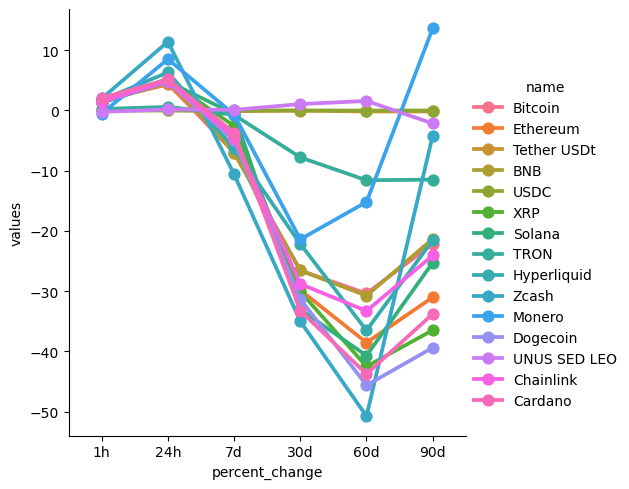

In [53]:
sns.catplot(x='percent_change', y='values', hue='name', data=df7, kind='point')

In [54]:
df10=df[['name','quote.USD.price','timestamp']]
df10 = df10.query("name == 'Bitcoin'")
df10

,name,quote.USD.price,timestamp
0,Bitcoin,58989.43277,2026-11-22 00:03:51.570649
0,Bitcoin,60244.80005,2026-11-22 00:37:40.912377
0,Bitcoin,60185.06387,2026-11-22 00:38:11.123497
0,Bitcoin,60211.47152,2026-11-22 00:38:39.041233
0,Bitcoin,60147.67903,2026-11-22 00:39:09.204694
0,Bitcoin,60119.01244,2026-11-22 00:39:39.416734
0,Bitcoin,60112.74137,2026-11-22 00:40:09.766916
0,Bitcoin,60030.27014,2026-11-22 00:40:40.381540


<Axes: xlabel='timestamp', ylabel='quote.USD.price'>

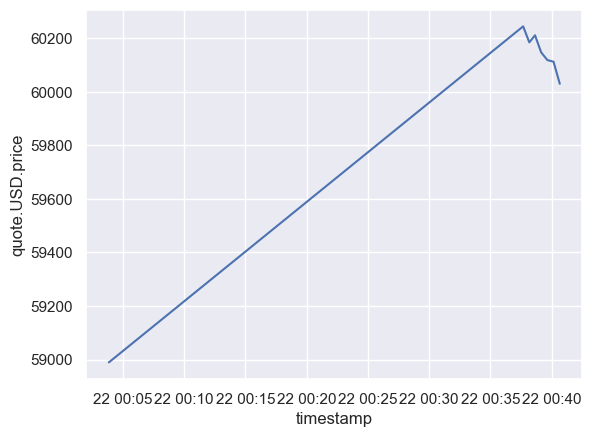

In [55]:
sns.set_theme(style="darkgrid")

sns.lineplot(x='timestamp', y='quote.USD.price', data = df10)